In [30]:
import pandas as pd
df=pd.read_csv("D:\Ansar\cubeAi\QuantEdge\Data\processed\stocks\ITC.csv")

In [31]:
df.shape

(5000, 7)

In [32]:
df.dtypes

date       object
symbol     object
open      float64
high      float64
low       float64
close     float64
volume    float64
dtype: object

In [33]:
df['timestamps']=pd.to_datetime(df['date'])
df.dtypes

date                  object
symbol                object
open                 float64
high                 float64
low                  float64
close                float64
volume               float64
timestamps    datetime64[ns]
dtype: object

In [34]:
df['timestamps'].dt.year.value_counts().sort_index()


timestamps
2005    190
2006    250
2007    249
2008    246
2009    243
2010    252
2011    247
2012    251
2013    250
2014    244
2015    248
2016    247
2017    248
2018    246
2019    245
2020    252
2021    248
2022    248
2023    246
2024    249
2025    101
Name: count, dtype: int64

In [35]:
train_df=df[(df['timestamps'].dt.year >= 2005) & (df['timestamps'].dt.year <=2024)]
test_df=df[(df['timestamps'].dt.year >=2025) & (df['timestamps'].dt.year <=2025)]
print("Training data shape:",train_df.shape)
print("Test data shape:",test_df.shape)

Training data shape: (4899, 8)
Test data shape: (101, 8)


In [36]:
train_df.head()

,date,symbol,open,high,low,close,volume,timestamps
0,2005-04-01,ITC,29.50,30.20,29.22,29.89,20670000.0,2005-04-01
1,2005-04-04,ITC,30.08,30.54,29.39,29.82,17080000.0,2005-04-04
2,2005-04-05,ITC,30.16,30.38,29.79,29.85,14110000.0,2005-04-05
3,2005-04-06,ITC,29.92,30.43,29.83,30.29,9820000.0,2005-04-06
4,2005-04-07,ITC,30.38,30.88,30.19,30.39,22890000.0,2005-04-07


In [37]:
import sys

sys.path.insert(0, r"D:\Ansar\cubeAi\QuantEdge")
from model.kronos import Kronos,KronosTokenizer,KronosPredictor
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

tokenizer = KronosTokenizer.from_pretrained("NeoQuasar/Kronos-Tokenizer-base")
model = Kronos.from_pretrained("NeoQuasar/Kronos-small").to(device)
predictor = KronosPredictor(model, tokenizer, device=device, max_context=512)

lookback=len(train_df)
pred_len=min(120,len(test_df))

x_df=train_df.loc[len(train_df)-lookback:,['open','high','low','close','volume']]

x_timestamp = train_df.iloc[-lookback:]['timestamps'].reset_index(drop=True)

y_timestamp = test_df.iloc[:pred_len]['timestamps'].reset_index(drop=True)

print("Generating forecast")
forecast_df=predictor.predict(
    df=x_df,
    x_timestamp=x_timestamp,
    y_timestamp=y_timestamp,
    pred_len=pred_len,
    
)


Generating forecast


100%|██████████| 101/101 [00:17<00:00,  5.72it/s]


In [38]:
y_timestamp

0     2025-01-01
1     2025-01-02
2     2025-01-03
3     2025-01-06
4     2025-01-07
         ...    
96    2025-05-23
97    2025-05-26
98    2025-05-27
99    2025-05-28
100   2025-05-29
Name: timestamps, Length: 101, dtype: datetime64[ns]

In [39]:
test_df.shape

(101, 8)

In [40]:
forecast_df.shape

(101, 6)

In [41]:
forecast_df.head()

,open,high,low,close,volume,amount
timestamps,,,,,,
2025-01-01,574.295410,536.961487,158.858032,232.526459,73038552.0,1.675666e+10
2025-01-02,224.337311,223.084503,120.054138,127.672760,34798704.0,6.558336e+09
2025-01-03,137.178009,183.468887,142.548096,173.090363,22524344.0,4.505704e+09
2025-01-06,175.698959,190.545700,154.690918,162.727890,23509230.0,4.711884e+09
2025-01-07,204.565918,197.233551,152.180695,141.309662,16654045.0,3.206914e+09


In [42]:
test_df[test_df['timestamps']=="2025-01-01"]

,date,symbol,open,high,low,close,volume,timestamps
4899,2025-01-01,ITC,459.76,460.57,456.12,457.82,18230000.0,2025-01-01


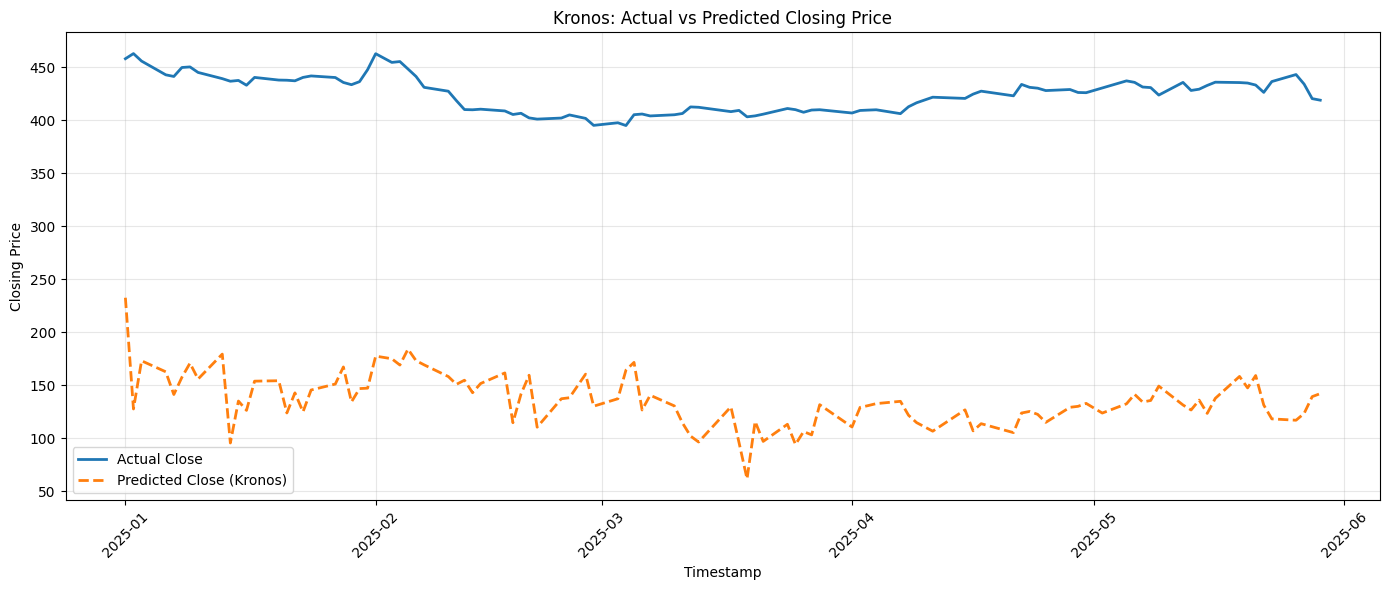

In [43]:

import matplotlib.pyplot as plt
import pandas as pd

# Get actual and predicted closing prices
actual_close = test_df.iloc[:len(forecast_df)]["close"].reset_index(drop=True)
predicted_close = forecast_df["close"].reset_index(drop=True)

# Use actual timestamps for the forecast period
timestamps = pd.to_datetime(
    test_df.iloc[:len(forecast_df)]["timestamps"]
).reset_index(drop=True)

# Plot both lines
plt.figure(figsize=(14, 6))

plt.plot(
    timestamps,
    actual_close,
    label="Actual Close",
    linewidth=2
)

plt.plot(
    timestamps,
    predicted_close,
    label="Predicted Close (Kronos)",
    linewidth=2,
    linestyle="--"
)

plt.title("Kronos: Actual vs Predicted Closing Price")
plt.xlabel("Timestamp")
plt.ylabel("Closing Price")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [44]:
train_df.head()

,date,symbol,open,high,low,close,volume,timestamps
0,2005-04-01,ITC,29.50,30.20,29.22,29.89,20670000.0,2005-04-01
1,2005-04-04,ITC,30.08,30.54,29.39,29.82,17080000.0,2005-04-04
2,2005-04-05,ITC,30.16,30.38,29.79,29.85,14110000.0,2005-04-05
3,2005-04-06,ITC,29.92,30.43,29.83,30.29,9820000.0,2005-04-06
4,2005-04-07,ITC,30.38,30.88,30.19,30.39,22890000.0,2005-04-07


In [45]:
x_df.head()

,open,high,low,close,volume
0,29.50,30.20,29.22,29.89,20670000.0
1,30.08,30.54,29.39,29.82,17080000.0
2,30.16,30.38,29.79,29.85,14110000.0
3,29.92,30.43,29.83,30.29,9820000.0
4,30.38,30.88,30.19,30.39,22890000.0


In [46]:
print("Historical data:")
print(x_df[["open", "high", "low", "close", "volume"]].tail())

print("\nHistorical close range:")
print(x_df["close"].min(), x_df["close"].max())

print("\nActual test close range:")
print(test_df["close"].min(), test_df["close"].max())

print("\nPredicted close range:")
print(forecast_df["close"].min(), forecast_df["close"].max())

Historical data:
        open    high     low   close      volume
4894  449.26  454.32  447.13  452.62  11560000.0
4895  454.61  455.84  450.30  451.20   8850000.0
4896  453.85  455.88  450.30  452.76  16280000.0
4897  454.80  455.46  450.30  451.25  13070000.0
4898  452.62  458.48  448.93  457.54  13280000.0

Historical close range:
29.82 494.53

Actual test close range:
394.85 462.65

Predicted close range:
61.77356 232.52646
